# Reconstrução exploratéria da superfície 3D

Nesta etapa, convertemos máscaras binárias experimentais em superfícies trianguladas com Marching Cubes e examinamos os modelos interativamente com PyVista. Os limiares não foram validados; as superfícies são **comparações didáticas**, não modelos anatômicos definitivos. Nada é salvo automaticamente.

## Como funciona o Marching Cubes

O algoritmo examina pequenos cubos formados por oito voxels vizinhos. Para uma máscara binária, escolhemos o nível `0.5`, entre os valores `0` (fundo) e `1` (objeto). Os vértices e triângulos gerados formam uma malha poligonal.

O volume está ordenado `(z, y, x)`. Marching Cubes recebe o espaçamento físico DICOM nessa mesma ordem; depois reordenamos as coordenadas para `(x, y, z)`, convenção do PyVista. As orientações absolutas do paciente não são aplicadas ? malha.

Para reduzir custo e facilitar a inspeção interativa, `step_size=2` analisa a cada dois voxels, reduzindo detalhes. A superfície ? limitada pelo campo de visão dos cortes disponíveis.

## Bibliotecas

- **OpenCV** (`cv2.threshold`): cria as máscaras binárias e calcula Otsu.
- **Scikit-image** (`skimage.measure.marching_cubes`): extrai os vértices e triângulos.
- **PyVista**: converte a malha em um objeto 3D e apresenta a visualização interativa no Jupyter via Trame.
- **NumPy** e **Matplotlib**: organizam e comparam os dados.

## 1. Carregar os cortes e definir limiares de comparação

Otsu serve como referência automática; os valores 100 e 150 são limiares manuais experimentais, escolhidos para comparar suas superfícies. As intensidades MRI não são unidades clênicas calibradas, portanto nenhum limiar deve ser interpretado clinicamente.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
import cv2
import sys
from skimage.measure import marching_cubes

current_dir = Path.cwd().resolve()
search_dirs = [current_dir, *current_dir.parents]
search_dirs.extend(parent / "reconstrucao-cranio" for parent in search_dirs.copy())
project_root = next(
    (folder for folder in search_dirs if (folder / "data" / "skull").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Não encontrei data/skull. "
        f"Diretório de trabalho atual do Jupyter: {current_dir}."
    )

src_path = str(project_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)
from leitura import ler_dicom_volume

data_dir = project_root / "data" / "skull" / "0051" / "0051"
volume, voxel_spacing_zyx, image_files = ler_dicom_volume(data_dir)
if volume.ndim != 3 or volume.shape[0] != len(image_files):
    raise ValueError(
        f"Volume DICOM inesperado: dimensões {volume.shape}, tipo {volume.dtype}."
    )

otsu_threshold, _ = cv2.threshold(
    volume.reshape(-1, 1), 0, 1, cv2.THRESH_BINARY | cv2.THRESH_OTSU
)

def criar_mascara_volume(dados: np.ndarray, limiar: float) -> np.ndarray:
    _, mascara_plana = cv2.threshold(
        dados.reshape(-1, 1), float(limiar), 1, cv2.THRESH_BINARY
    )
    return mascara_plana.reshape(dados.shape).astype(bool)

thresholds = {
    "Otsu do volume": float(otsu_threshold),
    "Experimental > 200": 200.0,
    "Experimental > 400": 400.0,
}
print(f"Volume MRI: {volume.shape}, tipo {volume.dtype}")
print(f"Espaçamento DICOM (z, y, x), em mm: {voxel_spacing_zyx}")
print(f"Limiares exploratérios: {thresholds}")

Volume MRI: (108, 512, 512), tipo uint16
Espaçamento DICOM (z, y, x), em mm: (1.5, 0.4785156, 0.4785156)
Limiares exploratérios: {'Otsu do volume': 623.0, 'Experimental > 200': 200.0, 'Experimental > 400': 400.0}


## 2. Extrair a superfície e preservar as coordenadas físicas relativas

Marching Cubes retorna vértices e faces triangulares. Cada face contém três índices que apontam para três vértices. PyVista espera as coordenadas `(x, y, z)` e as faces no formato `[3, índice0, índice1, índice2, ...]`, então reorganizamos os vértices e montamos esse vetor de conectividade.

O número de vértices e faces e os limites das coordenadas ajudam a conferir a saída. Um limite em `z=0` é evidência de que a superfície chega à borda do volume; por isso, o modelo é limitado pelos cortes disponíveis.

In [2]:
mesh_results = {}
step_size = 2

for label, threshold in thresholds.items():
    mask = criar_mascara_volume(volume, threshold)
    selected_fraction = float(mask.mean())
    if not mask.any():
        raise ValueError(f"A máscara {label!r} não contém voxels para formar superfície.")
    if mask.all():
        raise ValueError(f"A máscara {label!r} não tem fundo e não forma uma superfície fechada.")

    vertices_zyx, triangles, _, _ = marching_cubes(
        mask.astype(np.uint8),
        level=0.5,
        spacing=voxel_spacing_zyx,
        step_size=step_size,
        allow_degenerate=False,
    )
    vertices_xyz = vertices_zyx[:, [2, 1, 0]]
    faces_padded = np.column_stack(
        (np.full(len(triangles), 3, dtype=np.int64), triangles)
    ).ravel()
    mesh = pv.PolyData(vertices_xyz, faces_padded)
    mesh_results[label] = mesh

    print(
        f"{label}, T={threshold:g}: máscara {selected_fraction:.2%}; "
        f"{mesh.n_points:,} vértices; {mesh.n_cells:,} triângulos; "
        f"limites XYZ={mesh.bounds}"
    )

if len(mesh_results) != 3:
    raise ValueError(f"Esperadas 3 malhas para comparar; obtidas {len(mesh_results)}.")

Otsu do volume, T=623: máscara 33.66%; 141,900 vértices; 282,674 triângulos; limites XYZ=BoundsTuple(x_min =  11.005858421325684,
            x_max = 237.82225036621094,
            y_min =  11.005858421325684,
            y_max = 244.04295349121094,
            z_min =   0.0,
            z_max = 159.0)
Experimental > 200, T=200: máscara 39.76%; 225,993 vértices; 453,040 triângulos; limites XYZ=BoundsTuple(x_min =   0.0,
            x_max = 244.04295349121094,
            y_min =  11.005858421325684,
            y_max = 244.04295349121094,
            z_min =   0.0,
            z_max = 159.0)
Experimental > 400, T=400: máscara 35.00%; 166,035 vértices; 330,624 triângulos; limites XYZ=BoundsTuple(x_min =  11.005858421325684,
            x_max = 237.82225036621094,
            y_min =  11.005858421325684,
            y_max = 244.04295349121094,
            z_min =   0.0,
            z_max = 159.0)


## 3. Comparar as malhas interativamente

PyVista usa o backend Trame para apresentar um painel 3D interativo no Jupyter: arraste para girar, use a roda do mouse para ampliar e compare os modelos. Cada painel tem os mesmos limites dos eixos, mas uma superfície diferente. É normal as regiões superficiais mudarem conforme o limiar.

Se o painel 3D não aparecer, confira se o notebook está usando o kernel `.venv` e se `pyvista[jupyter]` foi instalado usando `requirements.txt`.

In [3]:
plotter = pv.Plotter(
    shape=(1, len(mesh_results)),
    window_size=(1500, 550),
    notebook=True,
)

for column, (label, mesh) in enumerate(mesh_results.items()):
    plotter.subplot(0, column)
    plotter.add_text(label, font_size=12)
    plotter.add_mesh(
        mesh,
        color="wheat",
        smooth_shading=True,
        show_edges=False,
    )
    plotter.show_axes()
    plotter.camera_position = "iso"

plotter.link_views()
plotter.show(jupyter_backend="trame")

## 4. Relacionar a superfície com os cortes 2D

A figura mostra, no mesmo corte central, a imagem original e cada máscara que originou uma malha. Essa comparação 2D ajuda a explicar por que cada limiar produz uma geometria 3D diferente.

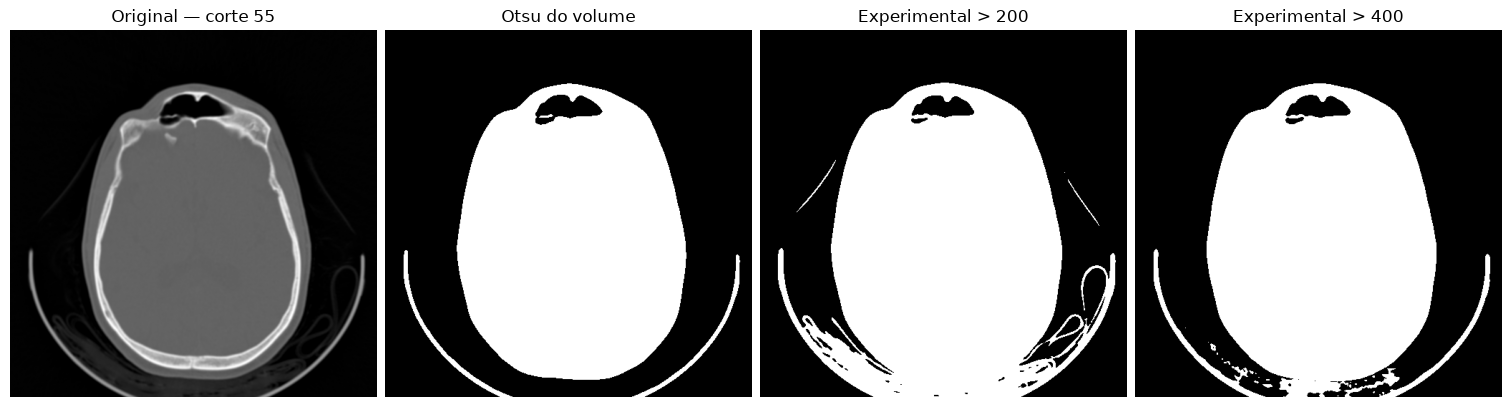

In [4]:
slice_index = volume.shape[0] // 2
fig, axes = plt.subplots(1, len(thresholds) + 1, figsize=(15, 4), layout="constrained")
axes[0].imshow(volume[slice_index], cmap="gray")
axes[0].set_title(f"Original — corte {slice_index + 1}")
axes[0].axis("off")

for ax, (label, threshold) in zip(axes[1:], thresholds.items()):
    ax.imshow(volume[slice_index] > threshold, cmap="gray", vmin=0, vmax=1)
    ax.set_title(label)
    ax.axis("off")

plt.show()

## Interpretar antes de considerar o modelo definitivo

Compare os contornos 2D e os modelos 3D: há regiões indesejadas na superfície? Uma mudança no limiar remove partes finas ou acrescenta outras estruturas? A superfície está limitada na borda do campo de visão?

A contagem de triângulos e a aparência do modelo **não comprovam** que a máscara seja anatomicamente correta. As intensidades e os limiares são exploratérios. Nenhuma superfície ? salva nesta etapa; mantenha a decisão do limiar explêcita antes de exportar um modelo final.